Ноутбук служит основой для изучения, однако многое нужно будет поискать и почитать самостоятельно
***

# Часть 1: теория (5 pt)

### Данные

В реальной практике **80% времени уходит на анализ и подготовку данных**, а не на построение моделей или визуализацию. Грязные данные ведут к ошибочным выводам:

| Проблема | Последствие для анализа |
|----------|------------------------|
| **Пропуски** | Смещение средних значений, потеря наблюдений |
| **Дубликаты** | Завышенные частоты, искажённая статистика |
| **Аномалии** | Искажение корреляций, неработающие модели МО |
| **Несогласованный текст** | Невозможность группировки по категориям |

В этой части поработаем именно с этими четырьмя пунктами. Однако во второй части вы можете использовать любые известные вам методы.

In [43]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Вот так можно смотреть версию (некоторые методы зависят от версии)
print(f"Pandas version: {pd.__version__}")

Pandas version: 3.0.6


Мы начнём с [датасета](https://www.kaggle.com/datasets/zynicide/wine-reviews?spm=a2ty_o01.29997173.0.0.17c95171dBJybJ) — **Wine Reviews**. Этот датасет как раз подойдет нам для обсуждения методов.
> В описании датасета можно прочитать описание столбцов и их значение.

In [44]:
wine = pd.read_csv('winemag-data-130k-v2.csv')

print(wine.shape)
print(wine.columns.tolist())

(129971, 14)
['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'taster_name', 'taster_twitter_handle', 'title', 'variety', 'winery']


In [45]:
wine.head(3)

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm


Видно, что датасет считался некорректно и у нас появился столбец `Unnamed: 0`. Это произошло потому что pandas автоматически присваивает индексы, но в нашем датасете первый столбец уже был индексами. Это можно исправить с помощью чтения с параметром
```python
wine = pd.read_csv('winemag-data-130k-v2.csv', index_col=0)
```

Но мы пойдем другим способом и просто **удалим** этот столбец с помощью метода [.drop()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html)

In [46]:
wine = wine.drop(columns=['Unnamed: 0'])

Также для того, чтобы нам было проще работать в этом задании удалим еще некоторые столбцы. То есть **оставим** только те, которые нам интересны.

In [47]:
wine = wine[['country', 'description', 'winery', 'designation', 'points', 'price', 'province', 'title', 'variety']]

In [48]:
wine.head()

,country,description,winery,designation,points,price,province,title,variety
0,Italy,"Aromas include tropical fruit, broom, brimston...",Nicosia,Vulkà Bianco,87,NaN,Sicily & Sardinia,Nicosia 2013 Vulkà Bianco (Etna),White Blend
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Quinta dos Avidagos,Avidagos,87,15.0,Douro,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red
2,US,"Tart and snappy, the flavors of lime flesh and...",Rainstorm,NaN,87,14.0,Oregon,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris
3,US,"Pineapple rind, lemon pith and orange blossom ...",St. Julian,Reserve Late Harvest,87,13.0,Michigan,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling
4,US,"Much like the regular bottling from 2012, this...",Sweet Cheeks,Vintner's Reserve Wild Child Block,87,65.0,Oregon,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir


### Диагностика проблем (1 pt)

Перед любыми действиями нужно **понять, какие проблемы есть в данных**. Базовый чек-лист:

| Проблема | Метод диагностики | Что ищем |
|----------|-------------------|----------|
| **Пропуски** | `.isna().sum()` | Количество `NaN` по столбцам |
| **Дубликаты** | `.duplicated().sum()` | Полные или частичные повторы строк |
| **Аномалии** | `.describe()` + визуализация | Значения за пределами ожидаемого диапазона |
| **Несогласованный текст** | `.value_counts()` | Опечатки, разный регистр, лишние пробелы |

Сууждения об аномалиях можно делать на основе жизненной (бизнес) логики (не может кот весить тонну) и/или странных сочетаний `min`, `mean`, `max` и других статистик.  
В репорте `value_counts` видно, сколько раз повторяется значение. Поэтому если строковое значение повторяется только один раз (хотя при это, например, категория), то стоит задуматься о том, что нужно данные как-то преобразовать. 

> Про некоторые методы вы уже знаете, а про остальные можно посмотреть в документации: [pandas.DataFrame.isna](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html), [pandas.DataFrame.duplicated](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html).

***

Предположим, что мы совсем не разбираемся в вине (надеюсь, что вам и предполагать не надо) и хотим что-то про него понять. Например какое и за сколько лучше всего.

In [49]:
# ЗАДАНИЕ:
#          1. Посчитайте количество пропусков (NaN) по каждому столбцу
#          2. Найдите количество полных дубликатов строк
#          3. Выведите базовую статистику для числовых столбцов
#          4. Проанализируйте распределение цены — есть ли подозрительные значения?
#          5. Напишите небольшой вывод о водможных проблемах с данными

count_NaN = wine.isnull().sum()
print(count_NaN)
print('-----------------------------------')
count_dublicate = wine.duplicated().sum()
print(count_dublicate)
print('-----------------------------------')
statistics = wine.describe()
print(statistics)
print('-----------------------------------')
statistics['price']

country           63
description        0
winery             0
designation    37465
points             0
price           8996
province          63
title              0
variety            1
dtype: int64
-----------------------------------
9983
-----------------------------------
              points          price
count  129971.000000  120975.000000
mean       88.447138      35.363389
std         3.039730      41.022218
min        80.000000       4.000000
25%        86.000000      17.000000
50%        88.000000      25.000000
75%        91.000000      42.000000
max       100.000000    3300.000000
-----------------------------------


count    120975.000000
mean         35.363389
std          41.022218
min           4.000000
25%          17.000000
50%          25.000000
75%          42.000000
max        3300.000000
Name: price, dtype: float64

В данных присутствует большое кол-во пропусков. Больше всего их в столбце designation - 37465, на втором месте price - 8996, на третьем места два стобца country и province, у них по 63 пропуска.
Обнаружено 9983 случая дублирования строк.
В столбце price интересная ситуация: медианное значение равно 25, среднее составляет 35.36, а максимальное равно 3300.

<details>
  <summary>Когда будете готовы, кликните сюда, чтобы посмотреть краткую сводку</summary>
    <ol>
      <li> Безусловно для нас важнее всего цена, а в этом столбце много пропусков, нужно с ними что-то делать. Также в цене есть явно аномальные (сильно маленькие или сильно большие значения), нужно понять, как с ними работать.</li>
      <li>В целом в разных столбцах есть пропуски, но вот в столбце designation их слишком много (37к).</li>
      <li>Рейтинги не содержат явных аномалий — все значения в ожидаемом диапазоне (80-100 баллов).</li>
    </ol> 
</details>

### Обработка дубликатов (0,5 pt)

In [50]:
wine.duplicated().sum()

np.int64(9983)

Дубликаты — это полные или частичные повторы строк, которые искажают статистику. В датасете вин есть 9 983 дубликата. Такие повторы будут портить нам статистику, поэтому их лучше удалить.
Поможет в этом [.drop_duplicates()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html)

In [51]:
# ЗАДАНИЕ: Удалите дубликаты, оставив только первую запись
wine = wine.drop_duplicates()

In [52]:
wine.duplicated().sum()

np.int64(0)

### Обработка пропусков (1 pt)

Выбор стратегии работы с пропусками зависит от **природы пропуска**. Например для цены нам критично заполнение пропусков, а вот в столбце `designation` (виноградник на территории винодельни, откуда собирают виноград, из которого делают вино) пропуски для нас некритичны и мы можем заменить их на нейтральное значение нужного типа (`str` "Undefined").

Прочитать про то, как можно работать с пропусками можно много где, например, [тут](https://www.geeksforgeeks.org/data-analysis/working-with-missing-data-in-pandas/) и [здесь](https://www.geeksforgeeks.org/data-analysis/handling-missing-values-machine-learning/).

Главное при заполнении пропусков следовать логике и делать так, чтобы стратегия заполнения не ломала данные. Например можно заполнять пропуски **средним (или наиболее частым) значением по какому-то условию**. Если пропусков мало или они не значимы, то можно удалять такие строки.

_Иногда важно смотреть внимательно: не всегда пропуски видны, иногда вместо `NaN` значения содержат нули или неопределенные слова. Такие случаи тоже можно считать пропусками, но в этом датасете такого нет._

***

Сейчас мы не будем сильно заморачиваться с этим и просто попробуем разные методы:
* в столбце `country` **заменим пропуски на наиболее часто встречаемую** страну (пропусков не так много, чтобы они повлияли, да и если страна неизвестна, то с оцень большой вероятностью это Итария или Франция)
* В столбце `designation` заменим пропуски на метку "Undefined". Это нормально, что для массовых вин никого не заботит виноградник. Но для того, чтобы мы корректно могли работать со строками заменим наны на строку.
* В столбце `price` заменим пропуски **медианой** по стране. Медианой, а не средним для того, чтобы не влияли выбросы и не появлялись дробные значения.
* В столбце `province` заполним пропуски **модой** по стране (наиболее частым).
* Строку с пропуском в столбце `variety` просто **удалим**)

Для начала сделаем **копию датасета** для того, чтобы не потерять изначальные данные!

Вам помогут: [.fillna()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html), [.transform()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.transform.html), [.dropna()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html).

In [53]:
wine.isna().sum()

country           59
description        0
winery             0
designation    34545
points             0
price           8395
province          59
title              0
variety            1
dtype: int64

In [54]:
wine_clean = wine.copy()

In [55]:
# ЗАДАНИЕ: обработайте пропуски согласно пунктам выше

most_common_country = 'Italy'
wine_clean['country'] = wine_clean['country'].fillna(most_common_country)

wine_clean['designation'] = wine_clean['designation'].fillna(value='Undefined')

wine_clean['price'] = pd.to_numeric(wine_clean['price'], errors='coerce')
country_median_price = (wine_clean.groupby('country')['price'].transform('median'))
wine_clean['price'] = wine_clean['price'].fillna(country_median_price)
wine_clean['price'] = wine_clean['price'].fillna(wine_clean['price'].median())

country_mode_province = wine_clean.groupby('country')['province'].transform(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
wine_clean['province'] = wine_clean['province'].fillna(country_mode_province)

wine_clean = wine_clean.dropna(subset=['variety'])

In [56]:
# Должно быть по нулям
wine_clean.isna().sum()

country        0
description    0
winery         0
designation    0
points         0
price          0
province       0
title          0
variety        0
dtype: int64

### Обработка аномалий (0,5 pt)

Аномалии (выбросы) — это значения, которые **значительно отклоняются** от остальных наблюдений. Они могут быть:
- **Ошибка измерения/ввода** (цена вина отрицательна) -> удалить
- **Редкое, но валидное наблюдение** (винтажное вино за много денег) -> сохранить или обработать отдельно
- **Систематическое искажение** (группировка значений на границах) -> исследовать источник

_Можно выделить три подхода для обнаружения аномалий или подбора порогов_

| Подход | Как работает | Плюсы | Минусы | Когда применять |
|--------|--------------|-------|--------|-----------------|
| **Бизнес-логика** | Определение границ на основе экспертных знаний предметной области | Интерпретируемо, учитывает контекст, не требует сложных вычислений | Требует экспертизы, субъективно | Когда есть чёткие физические/экономические ограничения (цена ≥ 0, возраст 0–120 лет) |
| **Статистика (IQR)** | Границы: `Q1 - 1.5×IQR` и `Q3 + 1.5×IQR`, где `IQR = Q3 - Q1` | Автоматизируемо, не зависит от распределения | Может удалить валидные экстремумы, чувствителен к выбору коэффициента (1.5 vs 3.0) | Когда нет экспертных знаний, но нужно быстро найти «подозрительные» значения |
| **Статистика (Z-score)** | Границы: $|z| > 3$, где $z = (x - \mu) / \sigma$ | Хорошо работает для нормальных распределений | Требует нормальности данных, чувствителен к выбросам при расчёте $\mu$ и $\sigma$ | Для признаков с приблизительно нормальным распределением |

Вот тут есть [гайд](https://sky.pro/wiki/media/kakie-sushhestvuyut-metody-opredeleniya-vybrosov-v-dannyh/) про то, как определять выбросы.

> Также для этого поможет документация: [.quantile()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html), [scipy.stats.zscore](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.zscore.html).

**Что же делать с аномалиями?**

| Стратегия | Когда применять | Пример |
|----------|-------------------|----------|
| **Удаление** | Аномалия — явная ошибка (цена $\leqslant$ $0) | `df = df[df['price'] > 0]` |
| **Ограничение (capping)** | Аномалия — экстремум, но не ошибка | `df['price'] = df['price'].clip(upper=500)` |
| **Сегментация** | Аномалии образуют отдельный сегмент | `df['segment'] = pd.cut(df['price'], bins=[0, 50, 100, float('inf')])` |
| **Сохранение с пометкой** | Нужно анализировать аномалии отдельно | `df['is_outlier'] = df['price'] > 500` |

Кажется, что в нашем случае лучшим решением будет **поделить** вина **на категории**: дешевые, нормальные, очень дорогие. Для того, чтобы лучше понять данные посмотрим на **диаграмму** цен ([DataFrame.plot.hist](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.hist.html))

<Axes: ylabel='Frequency'>

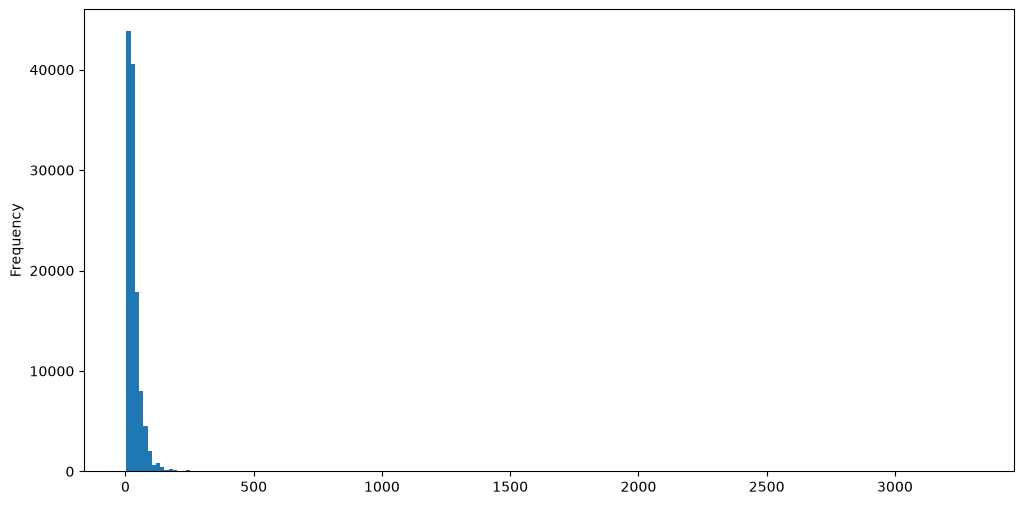

In [57]:
wine_clean.price.plot.hist(bins=200,figsize=(12,6))

_Какие пороги для ценовых категорий стоит поставить?_

In [58]:
# ЗАДАНИЕ: 1. Создать новый столбец wine_clean['price_category']
#          2. Согласно выявленным порогам определить ценовую категорию каждого вина

wine_clean['price_category'] = pd.cut(wine_clean['price'], bins=[0, 20, 200, np.inf], labels=['low', 'medium', 'high'], include_lowest=True)

In [59]:
wine_clean['price_category'].value_counts()

price_category
medium    75505
low       43817
high        665
Name: count, dtype: int64

### Обработка текста (0,5 pt)

Текстовые данные в реальных датасетах часто содержат **несогласованные обозначения**, которые мешают корректной группировке и анализу. Например могут быть следующие проблемы:

| Столбец | Проблема | Примеры из данных |
|---------|----------|-------------------|
| `country` | Разные форматы для одной страны | `'US'`, `'USA'`, `'U.S.A.'`, `'United States'` |
| `province` | Разный регистр и лишние пробелы | `' california '`, `'California'`, `'CALIFORNIA'` |
| `variety` | Опечатки и синонимы | `'Pinot Noir'` vs `'PinotNoir'` |

Нам повезло, в нашем датасете такого нет, однако, встретиться такое может часто.

**Как приводить текстовые/категориальные данные в общий вид?**

| Метод | Назначение | Пример |
|-------|------------|--------|
| `.str.strip()` | Удаляет пробелы по краям | `' California '` → `'California'` |
| `.str.lower()` / `.str.title()` | Приводит к единому регистру | `'california'` → `'California'` |
| `.replace()` | Заменяет значения по словарю | `{'US': 'United States'}` |
| `.str.contains()` | Поиск подстроки (регистронезависимый) | `contains('berry', case=False)` |

Как всегда подробнее в документации: [.str.strip()](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.strip.html),
[.str.lower()](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.lower.html),
[.replace()](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.replace.html),
[.str.contains()](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.contains.html).

In [60]:
# Проверьте, что в нашем датасете нет таких проблем
text_columns = wine_clean.select_dtypes(include=['object', 'string']).columns

for col in text_columns:
    print(f"Column: {col}")
    print(wine_clean[col].value_counts())
    print('-----------------------------------')

Column: country
country
US                        50457
France                    20353
Italy                     17999
Spain                      6116
Portugal                   5256
Chile                      4183
Argentina                  3544
Austria                    3034
Australia                  2197
Germany                    1992
South Africa               1301
New Zealand                1278
Israel                      466
Greece                      432
Canada                      226
Bulgaria                    132
Hungary                     129
Romania                     102
Uruguay                      98
Turkey                       81
Slovenia                     77
Georgia                      76
Croatia                      70
Mexico                       68
England                      63
Moldova                      56
Brazil                       49
Lebanon                      32
Morocco                      24
Peru                         16
Ukraine         

Что касается текстовых данных, то у нас есть очень информативный столбец `description`, из которого можно вытащить много информации. Для того, чтобы это было сделать легче, приведем все буквы к строчному виду и удалим знаки препинания.

In [61]:
# ЗАДАНИЕ: приведите описания к нижнему регистру и удалите знаки препинания

wine_clean['description'] = wine_clean['description'].astype('string').str.lower().str.replace(r'[^\w\s]', '', regex=True)

In [62]:
wine_clean.description[42]

'this is a festive wine with soft ripe fruit and acidity plus a red berry flavor'

### Вывод (1,5 pt)

Теперь по подготовленным данным ответьте на следующие вопросы (**напишите код и небольшие выводы**):
- Какая страна производит самые дорогие вина (по средней цене)? Какая — самые дешёвые? Какие страны производят очень дорогие вина?
- Есть ли связь между ценой и рейтингом? Вина какой ценовой категории получают самый высокий средний рейтинг?
- Какие 3 сорта винограда (variety) самые лучшие (по цене, по рейтингу)?
- Сравните средний рейтинг разных ценовых сегментов. Насколько отличается качество между бюджетным и премиум-сегментом?
- В каких ценовых сегментах встречаются фруктовые вина (посмотрите вхождения ключевых слов в описания)? 

In [63]:
#1
country_price = (wine_clean.groupby('country').agg(mean_price=('price', 'mean'), count=('price', 'count')).sort_values('mean_price', ascending=False))

print(country_price.head(10))
print('-----------------------------------')
print(country_price.tail(10))
print('-----------------------------------')

print(wine_clean.loc[wine_clean['price_category'] == 'high', 'country'].unique())

             mean_price  count
country                       
Switzerland   72.833333      6
England       52.507937     63
Germany       43.121988   1992
Hungary       42.100775    129
France        38.598290  20353
Italy         38.266181  17999
US            36.668450  50457
Canada        35.725664    226
Australia     35.499317   2197
Israel        31.581545    466
-----------------------------------
                        mean_price  count
country                                  
Moldova                  16.732143     56
Cyprus                   16.500000     10
Slovakia                 16.000000      1
Macedonia                15.636364     11
Romania                  15.333333    102
Bulgaria                 14.840909    132
Armenia                  14.500000      2
India                    13.750000      8
Bosnia and Herzegovina   12.500000      2
Ukraine                   9.214286     14
-----------------------------------
<StringArray>
[   'Argentina',    'Australia',      

           price    points
price   1.000000  0.399436
points  0.399436  1.000000
-----------------------------------
0.39943550030300945


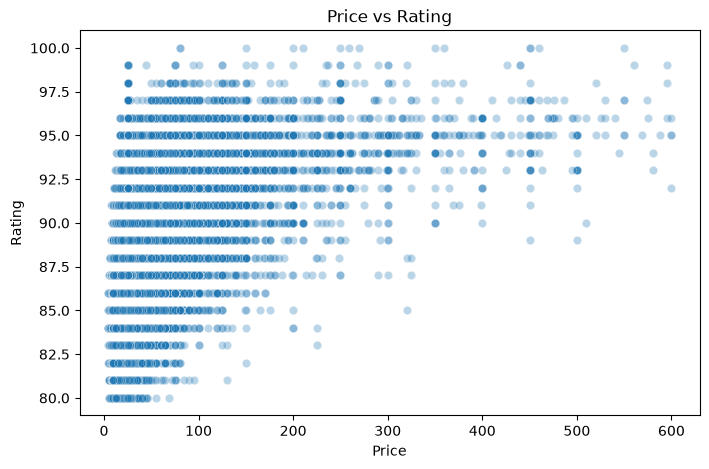

In [64]:
#2
print(wine_clean[['price', 'points']].corr())
print('-----------------------------------')
print(wine_clean['price'].corr(wine_clean['points']))
plt.figure(figsize=(8,5))

sns.scatterplot(data=wine_clean[wine_clean['price'] <= 600], x='price', y='points', alpha=0.3)
plt.xlabel('Price')
plt.ylabel('Rating')
plt.title('Price vs Rating')
plt.show()


In [65]:
#3
variety_stats = wine_clean.groupby('variety').agg(mean_price=('price', 'mean'), mean_points=('points', 'mean'), count=('variety', 'size'))

variety_stats['points_per_price'] = (
    variety_stats['mean_points'] / variety_stats['mean_price']
)

top3_value = (
    variety_stats
    .sort_values('points_per_price', ascending=False)
    .head(3)
)

print(top3_value)

                       mean_price  mean_points  count  points_per_price
variety                                                                
Trajadura                     7.0         86.0      1         12.285714
Malagouzia-Chardonnay         8.0         86.0      1         10.750000
Macabeo-Moscatel              8.0         85.0      1         10.625000


In [66]:
#4 Сравните средний рейтинг разных ценовых сегментов. Насколько отличается качество между бюджетным и премиум-сегментом?
segment_stats = (
    wine_clean
    .groupby('price_category', observed=True)
    .agg(
        mean_points=('points', 'mean'),
        median_points=('points', 'median'),
        count=('points', 'count')
    )
)

segment_stats

,mean_points,median_points,count
price_category,,,
low,86.547870,87.0,43817
medium,89.489266,90.0,75505
high,94.381955,95.0,665


In [67]:
#5 В каких ценовых сегментах встречаются фруктовые вина (посмотрите вхождения ключевых слов в описания)?
fruit_words = [
    'fruit', 'fruity',
    'apple', 'pear',
    'peach', 'apricot',
    'cherry', 'berry',
    'raspberry', 'strawberry',
    'blackberry', 'plum',
    'citrus', 'lemon',
    'orange', 'grapefruit'
]

fruit_pattern = '|'.join(fruit_words)

wine_clean['is_fruity'] = (
    wine_clean['description']
    .str.contains(fruit_pattern, case=False, na=False)
)
wine_clean['is_fruity'].value_counts()
fruity_by_category = (
    wine_clean[wine_clean['is_fruity']]
    ['price_category']
    .value_counts()
)

fruity_by_category

price_category
medium    67874
low       40437
high        589
Name: count, dtype: int64

1. Наиболее высокая средняя цена наблюдается у вин из Швейцарии, наиболее низка у вин из Украины. Самые дорогие вина производят Франция, Италия, Америка, Испания, Южная Африка, Португалия, Чили, Австрия, Румыния.
2. Исходя из графика Цена-Рейтинг я делаю вывод, что есть положительная связь: более дорогие вина в среднем получают более высокие оценки
3. Лучшими сортами винограда из логики points_per_price я бы назвал Trajadura, Malagouzia-Chardonnay, Macabeo-Moscatel
4. Разница между дешевым и премиальным вином составляет 8 пунктов рейтинга, что в целом является ощутимой разницей для ценителей, но для обычного человека, я предполагаю, что разница может быть минимальна.
5. Фруктовые вина встречаются во всех ценовых сегментах

...

# Часть 2: практика (5 pt)

**В этой части вам нужно самостоятельно провести анализ датасета и сделать выводы.**
***
**ЗАДАНИЕ: подготовить данные и сделать три неочевидных/интересных вывода (основывающихся на данных)**
***
В качестве датасета возьмем данные [Netflix](https://www.kaggle.com/datasets/shivamb/netflix-shows/data). 

> Оцениваться будут следующие пункты:
> * Диагностика проблем (1 pt)
> * Подготовка и очистка данных, в том числе добавление новых столбцов, выделение категорий и тд. Важна аргуменитация и пояснения выбора методов.(2 pt)
> * Анализ данных и выводы (2 pt)

В качестве отправной точки можете использовать вопросы:
- Какие 3 страны производят больше всего контента для Netflix? Есть ли различия между фильмами и сериалами?
- В каком году было выпущено максимальное количество сериалов?
- Какой возрастной рейтинг самый распространённый для фильмов? Для сериалов? Есть ли страна, где доминируют контент со взрослым рейтингом?
- Какова медианная продолжительность фильмов (в минутах)? Сериалов (в сезонах)?
- Какой жанр доминирует в США? В Индии?
- Какой тип контента «старше»?

**Пожалуйста, оформляйте ваш код и выводы аккуратно, при необходимости добавляйте секции и форматируйте текст.**

In [68]:
movie = pd.read_csv('netflix_titles.csv')
movie.shape

(8807, 12)

In [69]:
movie.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [70]:
movie.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [71]:
movie.isna().sum().sort_values(ascending=False)

director        2634
country          831
cast             825
date_added        10
rating             4
duration           3
show_id            0
type               0
title              0
release_year       0
listed_in          0
description        0
dtype: int64

In [72]:
movie.duplicated().sum()

np.int64(0)

Видно, что в дасаете пропуски в столбцах: director, cast, country, date_added, rating, duration. Дубликатов в данных нет, в основном в преобладают данные в формате str и есть одно поле типа int.

In [73]:
netflix = movie.copy()

# обработка текстовых полей
text_columns = [
    'type', 'title', 'director', 'cast',
    'country', 'rating', 'duration',
    'listed_in', 'description'
]

for col in text_columns:
    netflix[col] = netflix[col].astype('string').str.strip()

# Обработка пропусков
fill_unknown = ['director', 'cast', 'country', 'rating']

for col in fill_unknown:
    netflix[col] = netflix[col].fillna('Unknown')

netflix['duration_value'] = (
    netflix['duration']
    .str.extract(r'(\d+)')[0]
    .astype(float)
)

netflix['duration_value'] = (
    netflix['duration_value']
    .fillna(
        netflix.groupby('type')['duration_value']
        .transform('median')
    )
)

netflix['duration'] = netflix['duration'].fillna('Unknown')

netflix.isna().sum()
# Что делать с датами я не придумал, возможно их можно просто удалить или оставить как есть

show_id            0
type               0
title              0
director           0
cast               0
country            0
date_added        10
release_year       0
rating             0
duration           0
listed_in          0
description        0
duration_value     0
dtype: int64

In [74]:
# Создаем новые признаки
netflix['date_added'] = pd.to_datetime(
    netflix['date_added'],
    errors='coerce'
)

netflix['year_added'] = netflix['date_added'].dt.year
netflix['month_added'] = netflix['date_added'].dt.month_name()

netflix['content_age'] = (netflix['release_year'].max() - netflix['release_year'])
netflix['age_when_added'] = (netflix['year_added']- netflix['release_year'])

# Разделяю duration, у фильмов - минуты, а у сериалов - кол-во сезонов
netflix['duration_value'] = (netflix['duration'].str.extract(r'(\d+)')[0].astype(float))

netflix['genre_count'] = (netflix['listed_in'].str.split(',').apply(len))

netflix.isna().sum()

show_id            0
type               0
title              0
director           0
cast               0
country            0
date_added        98
release_year       0
rating             0
duration           0
listed_in          0
description        0
duration_value     3
year_added        98
month_added       98
content_age        0
age_when_added    98
genre_count        0
dtype: int64

1. Как быстро фильмы\сериалы попадают на Netflix

In [75]:
bins = [-1, 2, 5, 10, 20, 100]

labels = ['0-2 года', '3-5 лет', '6-10 лет', '11-20 лет', '20+ лет']

netflix['age_category'] = pd.cut(netflix['age_when_added'], bins=bins, labels=labels)

age_category_stats = (netflix['age_category'].value_counts(normalize=True).sort_index().mul(100).round(1))

age_category_stats

age_category
0-2 года     63.1
3-5 лет      12.7
6-10 лет     10.4
11-20 лет     8.1
20+ лет       5.7
Name: proportion, dtype: float64

In [76]:
age_type_stats = pd.crosstab(netflix['age_category'],netflix['type'],normalize='columns') * 100

age_type_stats.round(1)

type,Movie,TV Show
age_category,,
0-2 года,57.6,76.3
3-5 лет,13.2,11.3
6-10 лет,11.6,7.6
11-20 лет,10.0,3.5
20+ лет,7.5,1.2


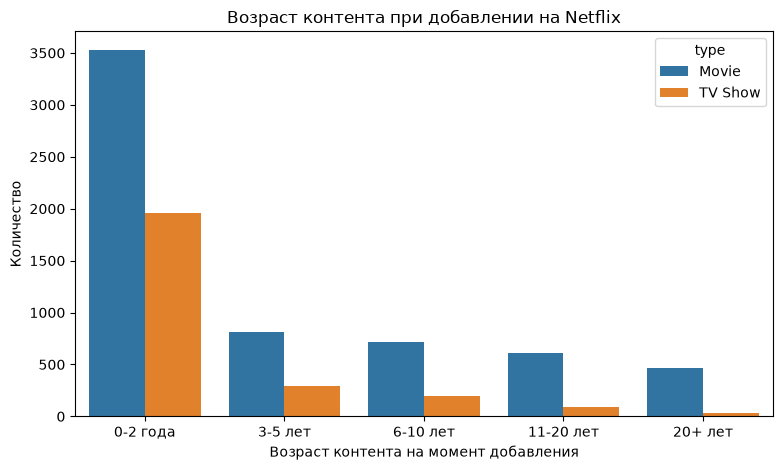

In [77]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=netflix,
    x='age_category',
    hue='type'
)

plt.xlabel('Возраст контента на момент добавления')
plt.ylabel('Количество')
plt.title('Возраст контента при добавлении на Netflix')

plt.show()

Исходя из графика видно, что большая часть каталога добавляется достаточно быстро после релиза

2. Менялась ли средняя продолжительность фильмов с течением времени?

In [78]:
# Оставляем только фильмы
movies = netflix[netflix['type'] == 'Movie'].copy()

movies = movies.dropna(subset=['release_year', 'duration_value'])

duration_by_year = (movies.groupby('release_year')['duration_value'].agg(['mean', 'median', 'count']).reset_index())

duration_by_year.head()

,release_year,mean,median,count
0,1942,35.000000,35.0,2
1,1943,62.666667,61.0,3
2,1944,52.000000,40.0,3
3,1945,51.333333,59.0,3
4,1946,58.000000,58.0,1


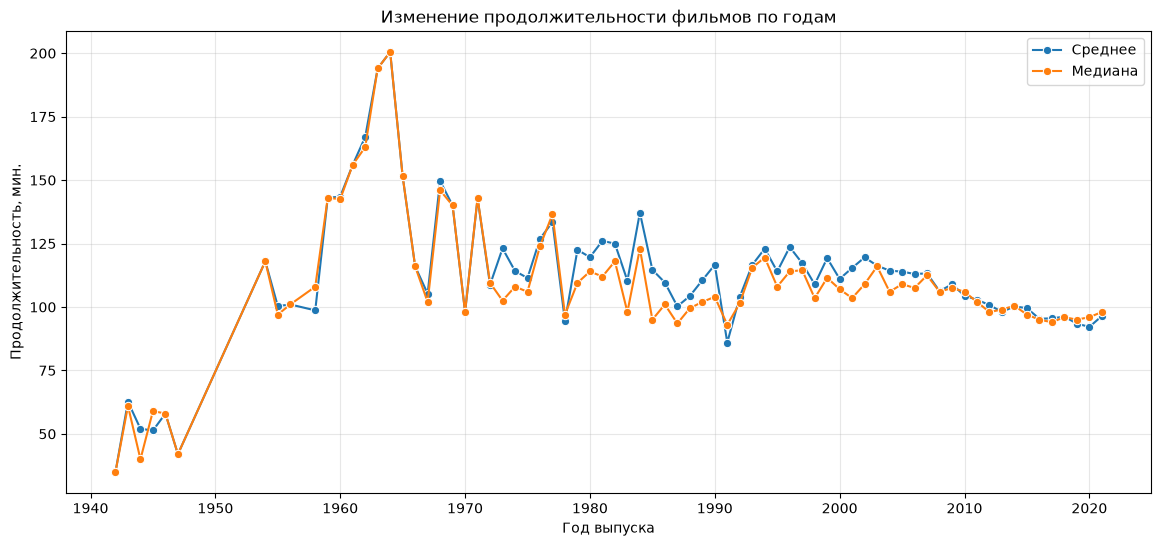

In [79]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=duration_by_year,
    x='release_year',
    y='mean',
    marker='o',
    label='Среднее'
)

sns.lineplot(
    data=duration_by_year,
    x='release_year',
    y='median',
    marker='o',
    label='Медиана'
)

plt.title('Изменение продолжительности фильмов по годам')
plt.xlabel('Год выпуска')
plt.ylabel('Продолжительность, мин.')
plt.grid(alpha=0.3)
plt.legend()

plt.show()

Исходя из графика, видно, что с 60-х длина фильмов снижается, но начиная с 2019 длина потихоньку увеличивается

3. Изменение популярности жанров по годам

In [80]:
# Берём только нужные столбцы
genres_by_year = netflix[['release_year', 'listed_in']].dropna().copy()

# Разделяем список жанров
genres_by_year['listed_in'] = genres_by_year['listed_in'].str.split(', ')

# Каждый жанр переносим в отдельную строку
genres_by_year = genres_by_year.explode('listed_in')

# Переименовываем столбец
genres_by_year = genres_by_year.rename(columns={'listed_in': 'genre'})

genres_by_year.head()

,release_year,genre
0,2020,Documentaries
1,2021,International TV Shows
1,2021,TV Dramas
1,2021,TV Mysteries
2,2021,Crime TV Shows


In [81]:
# Количество каждого жанра по годам
genre_counts = (genres_by_year.groupby(['release_year', 'genre']).size().reset_index(name='count'))

# Общее количество жанровых упоминаний в каждом году
total_by_year = (genres_by_year.groupby('release_year').size().reset_index(name='total'))

# Объединяем таблицы
genre_counts = genre_counts.merge(total_by_year, on='release_year')

# Доля жанра внутри конкретного года
genre_counts['share'] = (genre_counts['count'] / genre_counts['total'] * 100)

genre_counts.head()

,release_year,genre,count,total,share
0,1925,TV Shows,1,1,100.0
1,1942,Classic Movies,2,4,50.0
2,1942,Documentaries,2,4,50.0
3,1943,Classic Movies,1,4,25.0
4,1943,Documentaries,3,4,75.0


In [82]:
top3_by_year = (genre_counts.sort_values(['release_year', 'share'], ascending=[True, False]).groupby('release_year').head(3))

top3_by_year.head(15)

,release_year,genre,count,total,share
0,1925,TV Shows,1,1,100.000000
1,1942,Classic Movies,2,4,50.000000
2,1942,Documentaries,2,4,50.000000
4,1943,Documentaries,3,4,75.000000
3,1943,Classic Movies,1,4,25.000000
5,1944,Classic Movies,3,6,50.000000
6,1944,Documentaries,3,6,50.000000
7,1945,Classic Movies,3,7,42.857143
8,1945,Documentaries,3,7,42.857143
9,1945,TV Shows,1,7,14.285714


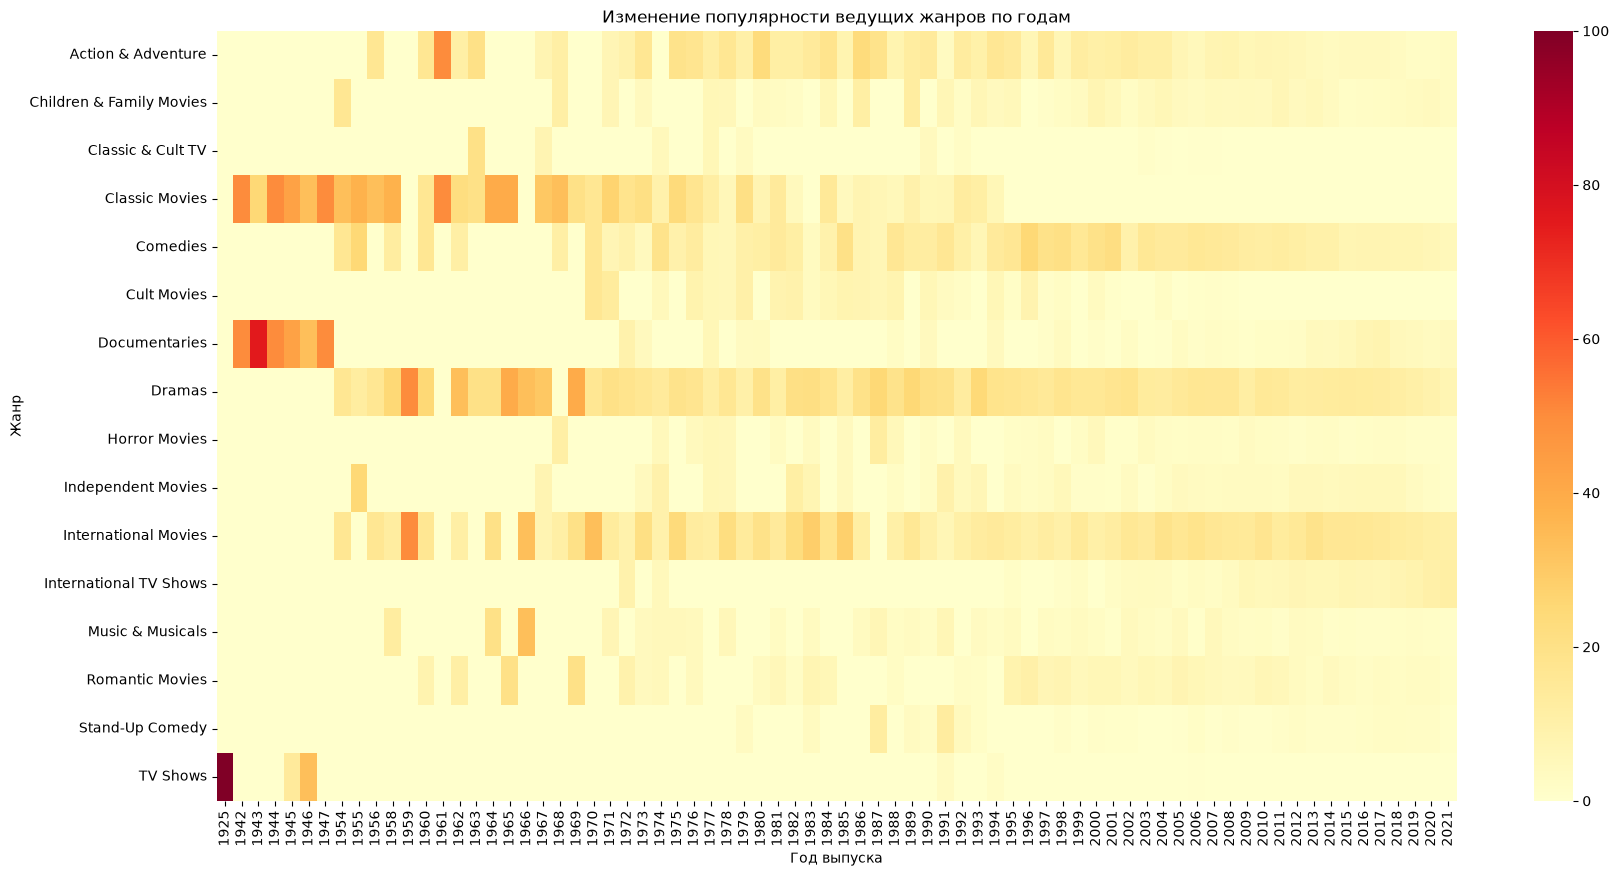

In [ ]:
# Жанры, которые хотя бы раз были в топ-3 какого-либо года
important_genres = top3_by_year['genre'].unique()

# Таблица для heatmap
genre_heatmap = (genre_counts[genre_counts['genre'].isin(important_genres)].pivot(index='genre',columns='release_year',values='share').fillna(0))

plt.figure(figsize=(20, 10))

sns.heatmap(genre_heatmap, cmap='YlOrRd')

plt.title('Изменение популярности ведущих жанров по годам')
plt.xlabel('Год выпуска')
plt.ylabel('Жанр')

plt.show()

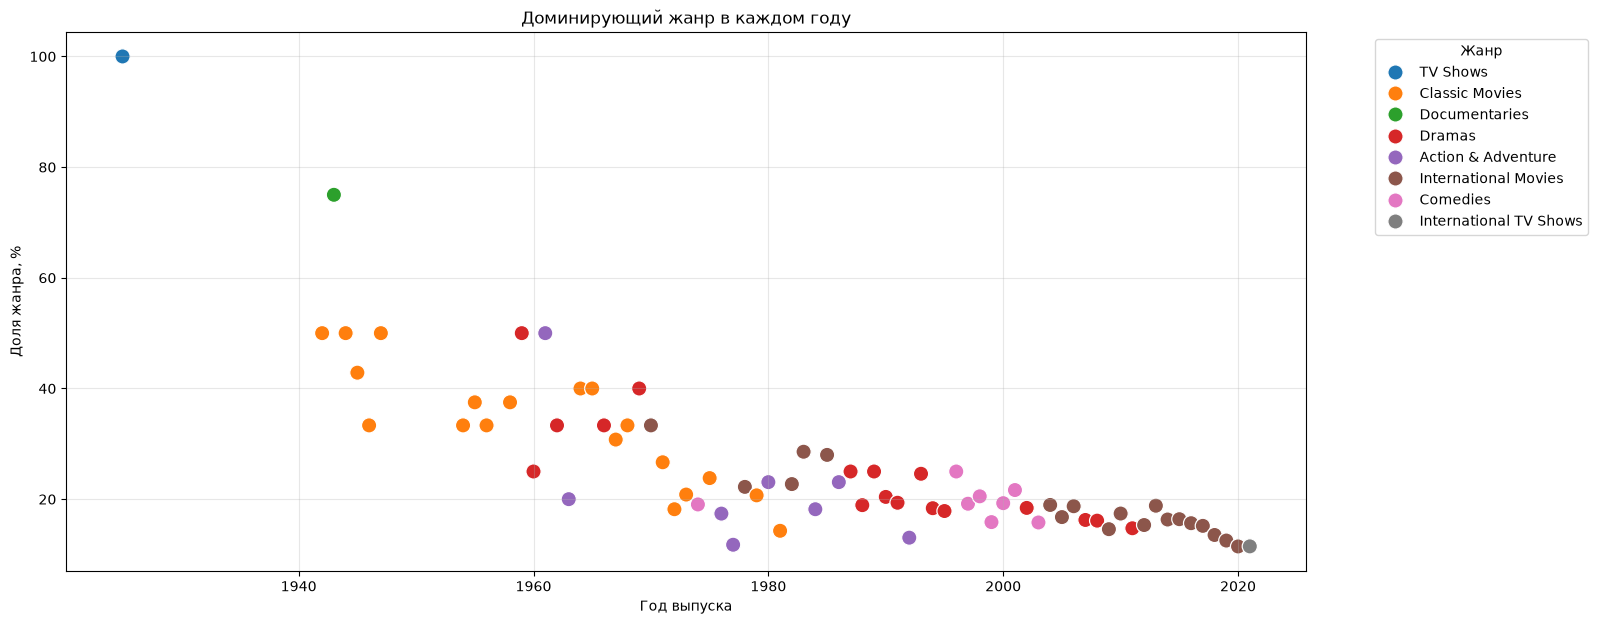

In [ ]:
dominant_genres = (genre_counts.sort_values(['release_year', 'share'],ascending=[True, False]).groupby('release_year').head(1))

plt.figure(figsize=(16, 7))

sns.scatterplot(
    data=dominant_genres,
    x='release_year',
    y='share',
    hue='genre',
    s=120
)

plt.title('Доминирующий жанр в каждом году')
plt.xlabel('Год выпуска')
plt.ylabel('Доля жанра, %')

plt.grid(alpha=0.3)

plt.legend(
    title='Жанр',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.show()

Из полученных графиков видно, что общее кол-во жанров с каждым годом растет из-за чего доля самых популярных жанров в году снижается. Также видно, что начиная с 2004 года жанр International Movies очень популярен и имеет самую длинную серию популярности. 
Также видно, что в 1925 жанр TV Shows абсолютный жанр.

**УДОСТОВЕРЬТЕСЬ, ЧТО ВСЕ ВАШИ ВЫВОДЫ И КОД ОФОРМЛЕНЫ ТАК, ЧТОБЫ ЛЕГКО МОЖНО БЫЛО ПОНЯТЬ, К ЧЕМУ ОНИ ОТНОСЯТСЯ**  
**НЕ ЗАБУДЬТЕ ПЕРЕЗАПУСТИТЬ НОУТБУК ТАК, ЧТОБЫ ВСЕ ЯЧЕЙКИ БЫЛИ ЗАПУЩЕНЫ ПОДРЯД, НАЧИНАЯ С [1]**